# How many V-JEPA phases? — sweep k = 2..10

Cluster the saved daily embeddings (`runs/vjepa/embeddings.npy`) into k = 2..10 phases and
compare.  There is no ground-truth k for an unsupervised partition, so we judge each k on
three independent axes:

1. **External** — agreement with the classical WH04 RMM phase on active days (ARI, NMI).
   ARI/NMI are chance-adjusted and work across different cluster counts.
2. **Internal** — cluster compactness/separation: silhouette (higher better), k-means
   inertia (elbow), Davies–Bouldin (lower better).
3. **Temporal coherence** — does an MJO phase evolve slowly day-to-day (stay-or-adjacent),
   well above a shuffled-label baseline?

RMM uses **8** phases by convention; we check whether the data supports that.

## 0. Setup & inputs

In [1]:
import os, sys, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "/glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO"
sys.path.insert(0, ROOT); os.chdir(ROOT)
from jepa.downstream.cluster import SOM1D, order_by_convection, circular_accuracy
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, davies_bouldin_score)

with open(os.path.join(ROOT, "jepa/config_vjepa.yaml")) as f:
    cfg = yaml.safe_load(f)
d = cfg["data"]; OUT = os.path.join(ROOT, "runs/vjepa")

emb   = np.load(os.path.join(OUT, "embeddings.npy"))
dates = np.load(os.path.join(OUT, "emb_dates.npy")).astype("datetime64[D]")
Z = (emb - emb.mean(0)) / (emb.std(0) + 1e-6)

anom       = np.load(os.path.join(d["cache_dir"], "anom.npy"), mmap_mode="r")
anom_dates = np.load(os.path.join(d["cache_dir"], "dates.npy")).astype("datetime64[D]")
stats      = np.load(os.path.join(d["cache_dir"], "stats.npz"))

# classical RMM phase, aligned to embedding days (active days only)
rmm = pd.read_csv(d["rmm_csv"], parse_dates=["time"])
rmm["date"] = rmm["time"].values.astype("datetime64[D]")
rb = rmm.set_index("date")
common = np.intersect1d(dates, rb.index.values)
ei     = pd.Index(dates).get_indexer(common)
amp    = rb.loc[common, "amplitude"].values
rphase = rb.loc[common, "phase"].values.astype(int) - 1
active = amp >= 1.0
print(f"{emb.shape[0]} days, embed dim {emb.shape[1]} | {active.sum()} active days for RMM eval")

/glade/work/weidong/.conda_envs/2DTurbEmulator/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


15220 days, embed dim 192 | 9225 active days for RMM eval


## 1. Sweep k = 2..10

Saves `phase_{k}_labels.npz` (eastward-ordered k-means + SOM labels) for every k, and
collects the metrics.  `circular_acc` is only meaningful where the cluster count matches
RMM's 8 phases, so it is reported at k = 8 only.

In [2]:
KS = list(range(2, 11))
same = np.diff(dates).astype("timedelta64[D]").astype(int) == 1
rng  = np.random.default_rng(0)

def temporal_coherence(lab, k):
    dd = np.abs(np.diff(lab)); circ = np.minimum(dd, k - dd)[same]
    sh = lab.copy(); rng.shuffle(sh)
    ds = np.minimum(np.abs(np.diff(sh)), k - np.abs(np.diff(sh)))[same]
    return float(np.mean(circ <= 1)), float(np.mean(ds <= 1))

rows = []
for k in KS:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    lab_km = km.labels_
    lab_som = SOM1D(k, iters=30000, seed=0).fit(Z).predict(Z)
    lab_km,  cen_km,  _ = order_by_convection(lab_km,  k, dates, anom, anom_dates, stats)
    lab_som, cen_som, _ = order_by_convection(lab_som, k, dates, anom, anom_dates, stats)
    np.savez(os.path.join(OUT, f"phase_{k}_labels.npz"),
             dates=dates, kmeans=lab_km, som=lab_som)

    c_km, c_som, r = lab_km[ei][active], lab_som[ei][active], rphase[active]
    real, shuf = temporal_coherence(lab_km, k)
    rows.append(dict(
        k=k,
        ari_km=adjusted_rand_score(r, c_km),  nmi_km=normalized_mutual_info_score(r, c_km),
        ari_som=adjusted_rand_score(r, c_som), nmi_som=normalized_mutual_info_score(r, c_som),
        circ_acc=(circular_accuracy(c_km, r, k) if k == 8 else np.nan),
        silhouette=silhouette_score(Z, lab_km, sample_size=3000, random_state=0),
        inertia=km.inertia_, davies_bouldin=davies_bouldin_score(Z, lab_km),
        coh_real=real, coh_shuffled=shuf, coh_gain=real - shuf,
    ))
    print(f"k={k:2d}  ARI={rows[-1]['ari_km']:.3f}  NMI={rows[-1]['nmi_km']:.3f}  "
          f"sil={rows[-1]['silhouette']:.3f}  DB={rows[-1]['davies_bouldin']:.2f}  "
          f"coh={real:.2f}(shuf {shuf:.2f})")

df = pd.DataFrame(rows).set_index("k")
df.to_csv(os.path.join(OUT, "phase_k_sweep_metrics.csv"))
df.round(3)

k= 2  ARI=0.010  NMI=0.016  sil=0.090  DB=3.23  coh=1.00(shuf 1.00)
k= 3  ARI=0.111  NMI=0.189  sil=0.068  DB=2.93  coh=1.00(shuf 1.00)
k= 4  ARI=0.188  NMI=0.298  sil=0.079  DB=2.87  coh=0.94(shuf 0.75)
k= 5  ARI=0.191  NMI=0.317  sil=0.080  DB=2.80  coh=0.93(shuf 0.60)
k= 6  ARI=0.180  NMI=0.298  sil=0.077  DB=2.82  coh=0.92(shuf 0.50)
k= 7  ARI=0.174  NMI=0.292  sil=0.070  DB=2.88  coh=0.90(shuf 0.43)
k= 8  ARI=0.167  NMI=0.296  sil=0.066  DB=2.84  coh=0.88(shuf 0.37)
k= 9  ARI=0.174  NMI=0.298  sil=0.061  DB=2.88  coh=0.90(shuf 0.34)
k=10  ARI=0.180  NMI=0.315  sil=0.059  DB=2.88  coh=0.87(shuf 0.30)


,ari_km,nmi_km,ari_som,nmi_som,circ_acc,silhouette,inertia,davies_bouldin,coh_real,coh_shuffled,coh_gain
k,,,,,,,,,,,
2,0.010,0.016,0.010,0.017,NaN,0.090,2669655.00,3.229,1.000,1.000,0.000
3,0.111,0.189,0.073,0.137,NaN,0.068,2526877.75,2.930,1.000,1.000,0.000
4,0.188,0.298,0.176,0.278,NaN,0.079,2398302.00,2.874,0.942,0.747,0.195
5,0.191,0.317,0.184,0.295,NaN,0.080,2320241.75,2.796,0.927,0.596,0.331
6,0.180,0.298,0.170,0.279,NaN,0.077,2263541.75,2.822,0.918,0.503,0.415
7,0.174,0.292,0.182,0.299,NaN,0.070,2214206.25,2.876,0.901,0.428,0.474
8,0.167,0.296,0.176,0.301,0.276,0.066,2173198.00,2.844,0.884,0.374,0.510
9,0.174,0.298,0.176,0.307,NaN,0.061,2140650.50,2.877,0.900,0.338,0.562
10,0.180,0.315,0.169,0.301,NaN,0.059,2111135.00,2.880,0.872,0.302,0.570


## 2. External agreement with RMM vs k

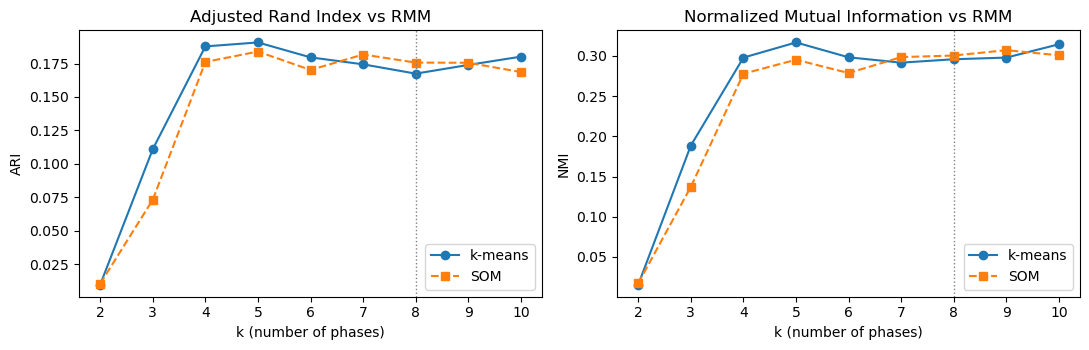

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(df.index, df.ari_km, "o-", label="k-means")
ax[0].plot(df.index, df.ari_som, "s--", label="SOM")
ax[0].axvline(8, color="grey", ls=":", lw=1); ax[0].set(title="Adjusted Rand Index vs RMM",
            xlabel="k (number of phases)", ylabel="ARI"); ax[0].legend()
ax[1].plot(df.index, df.nmi_km, "o-", label="k-means")
ax[1].plot(df.index, df.nmi_som, "s--", label="SOM")
ax[1].axvline(8, color="grey", ls=":", lw=1); ax[1].set(title="Normalized Mutual Information vs RMM",
            xlabel="k (number of phases)", ylabel="NMI"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Internal cluster quality vs k

Silhouette (higher = better separated), k-means inertia (look for the elbow), and
Davies–Bouldin (lower = better).

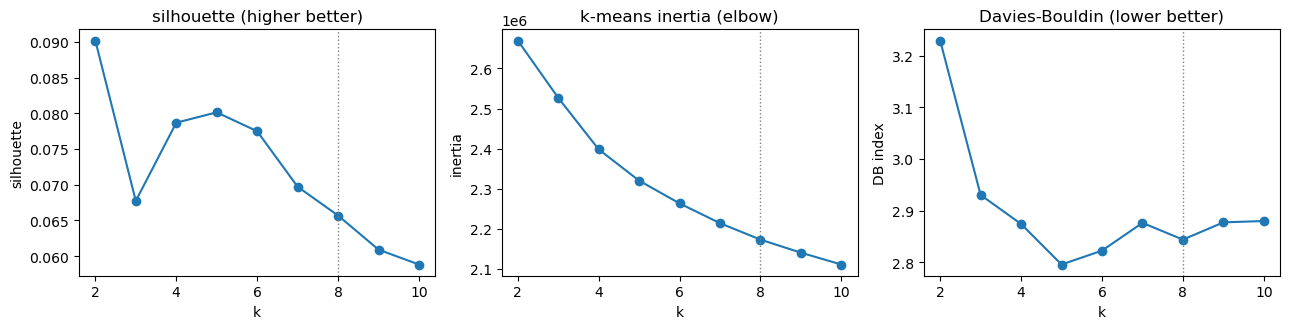

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(df.index, df.silhouette, "o-"); ax[0].axvline(8, color="grey", ls=":", lw=1)
ax[0].set(title="silhouette (higher better)", xlabel="k", ylabel="silhouette")
ax[1].plot(df.index, df.inertia, "o-"); ax[1].axvline(8, color="grey", ls=":", lw=1)
ax[1].set(title="k-means inertia (elbow)", xlabel="k", ylabel="inertia")
ax[2].plot(df.index, df.davies_bouldin, "o-"); ax[2].axvline(8, color="grey", ls=":", lw=1)
ax[2].set(title="Davies-Bouldin (lower better)", xlabel="k", ylabel="DB index")
plt.tight_layout(); plt.show()

## 4. Temporal coherence vs k

Fraction of consecutive days that stay in the same or a circularly-adjacent phase, for the
inferred labels vs a shuffled-label baseline.  The **gain** (real − shuffled) is the part
attributable to real slow MJO evolution rather than to having few clusters.

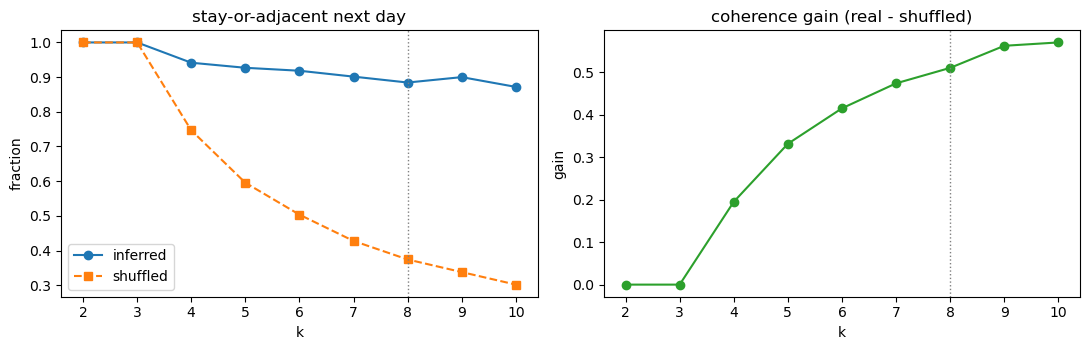

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(df.index, df.coh_real, "o-", label="inferred")
ax[0].plot(df.index, df.coh_shuffled, "s--", label="shuffled")
ax[0].axvline(8, color="grey", ls=":", lw=1)
ax[0].set(title="stay-or-adjacent next day", xlabel="k", ylabel="fraction"); ax[0].legend()
ax[1].plot(df.index, df.coh_gain, "o-", color="C2"); ax[1].axvline(8, color="grey", ls=":", lw=1)
ax[1].set(title="coherence gain (real - shuffled)", xlabel="k", ylabel="gain")
plt.tight_layout(); plt.show()

## 5. Summary — pick k

In [6]:
best = {
    "max ARI vs RMM":        int(df.ari_km.idxmax()),
    "max NMI vs RMM":        int(df.nmi_km.idxmax()),
    "max silhouette":        int(df.silhouette.idxmax()),
    "min Davies-Bouldin":    int(df.davies_bouldin.idxmin()),
    "max coherence gain":    int(df.coh_gain.idxmax()),
}
for crit, kk in best.items():
    print(f"  {crit:22s}-> k = {kk}")
print("\nRMM convention: k = 8")
print("saved phase_2_labels.npz .. phase_10_labels.npz + phase_k_sweep_metrics.csv in", OUT)
df.round(3)

  max ARI vs RMM        -> k = 5
  max NMI vs RMM        -> k = 5
  max silhouette        -> k = 2
  min Davies-Bouldin    -> k = 5
  max coherence gain    -> k = 10

RMM convention: k = 8
saved phase_2_labels.npz .. phase_10_labels.npz + phase_k_sweep_metrics.csv in /glade/campaign/univ/uchi0018/weidong/SSL_project/Self_supervised_learning/MJO/runs/vjepa


,ari_km,nmi_km,ari_som,nmi_som,circ_acc,silhouette,inertia,davies_bouldin,coh_real,coh_shuffled,coh_gain
k,,,,,,,,,,,
2,0.010,0.016,0.010,0.017,NaN,0.090,2669655.00,3.229,1.000,1.000,0.000
3,0.111,0.189,0.073,0.137,NaN,0.068,2526877.75,2.930,1.000,1.000,0.000
4,0.188,0.298,0.176,0.278,NaN,0.079,2398302.00,2.874,0.942,0.747,0.195
5,0.191,0.317,0.184,0.295,NaN,0.080,2320241.75,2.796,0.927,0.596,0.331
6,0.180,0.298,0.170,0.279,NaN,0.077,2263541.75,2.822,0.918,0.503,0.415
7,0.174,0.292,0.182,0.299,NaN,0.070,2214206.25,2.876,0.901,0.428,0.474
8,0.167,0.296,0.176,0.301,0.276,0.066,2173198.00,2.844,0.884,0.374,0.510
9,0.174,0.298,0.176,0.307,NaN,0.061,2140650.50,2.877,0.900,0.338,0.562
10,0.180,0.315,0.169,0.301,NaN,0.059,2111135.00,2.880,0.872,0.302,0.570


## How to read this

- **Silhouette / Davies–Bouldin** usually favour *small* k (2–3): fewer, fatter blobs are
  always "cleaner" geometrically — this measures separation, not physical relevance, so do
  not pick k from these alone.
- **ARI/NMI vs RMM** reward matching the 8-phase MJO structure; a peak or plateau near
  k = 8 supports the RMM convention.  If they keep rising past 8, the embeddings carry finer
  structure than RMM resolves.
- **Coherence gain** rewards a k at which phases still evolve slowly in time.
- For an apples-to-apples comparison with WH04 RMM and the propagation labels, **k = 8** is
  the principled default; use this sweep to confirm 8 is reasonable (not sharply worse than
  neighbours) rather than to chase the single highest number.

To composite the raw fields for a chosen k, point `1.1-phase_jepa.ipynb` at the matching
`phase_{k}_labels.npz`.